# Machine Learning mini project


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/


In [1]:
#paste the kaggle API key here to download dataset


In [ ]:
#downloaded in zip formate....extraxt the file through
import zipfile
zip_ref = zipfile.ZipFile('/*path to zip file*/', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [68]:
# FILE CONTAINS
# kaggle.json
# model.pkl
# modfied_placement_data.csv
# placement.csv

In [ ]:
# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection
# 6. Deploy the model

In [2]:
import numpy as np
import pandas as pd

In [19]:
#load dataset
df = pd.read_csv('/content/placement.csv')

In [20]:
df

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0
...,...,...,...,...
95,95,4.3,200.0,0
96,96,4.4,42.0,0
97,97,6.7,182.0,1
98,98,6.3,103.0,1


In [31]:
#extract the "cgpa" and "iq" column (input)
x = df.iloc[:,1:3]
x.shape
x

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [33]:
#extract the "placement" column (output)
y = df.iloc[:, -1]
y

,placement
0,1
1,0
2,0
3,1
4,0
...,...
95,0
96,0
97,1
98,1


In [34]:
# split the dataset into Train Test
from sklearn.model_selection import train_test_split

train_x, test_x, train_y, test_y = train_test_split(x, y, test_size=0.1)

In [35]:
train_x

,cgpa,iq
88,4.4,149.0
90,7.3,86.0
42,7.6,89.0
86,5.1,128.0
11,6.9,138.0
...,...,...
37,8.1,149.0
91,7.5,158.0
19,5.2,132.0
56,6.1,65.0


In [36]:
test_x

,cgpa,iq
40,4.9,134.0
69,8.5,120.0
99,6.2,113.0
33,6.0,149.0
61,7.3,137.0
10,6.0,45.0
4,5.8,142.0
5,7.1,48.0
50,3.5,233.0
67,5.0,118.0


In [37]:
train_y

,placement
88,0
90,1
42,1
86,0
11,1
...,...
37,1
91,1
19,0
56,0


In [38]:
test_y

,placement
40,0
69,1
99,1
33,0
61,1
10,1
4,0
5,1
50,0
67,0


In [46]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
train_x = scaler.fit_transform(train_x)
test_x = scaler.fit_transform(test_x)


In [47]:
train_x
test_x

array([[-0.84981625,  0.20084286],
       [ 1.85756295, -0.07755318],
       [ 0.12784846, -0.21675121],
       [-0.02256149,  0.49912434],
       [ 0.95510322,  0.26049916],
       [-0.02256149, -1.56896059],
       [-0.17297145,  0.35992632],
       [ 0.80469326, -1.50930429],
       [-1.90268594,  2.16950063],
       [-0.77461127, -0.11732405]])

In [50]:
train_y

,placement
88,0
90,1
42,1
86,0
11,1
...,...
37,1
91,1
19,0
56,0


In [51]:
#now train the model
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()

In [53]:
#training the model
clf.fit(train_x, train_y)

LogisticRegression()

In [57]:
#test the model and save into the predicted
predicted = clf.predict(test_x)
predicted

array([0, 1, 1, 1, 1, 0, 0, 1, 0, 0])

In [62]:
#here the actual result of test_y
test_y


,placement
40,0
69,1
99,1
33,0
61,1
10,1
4,0
5,1
50,0
67,0


In [58]:
#for checking the accuracy of the model using accuracy_score module
from sklearn.metrics import accuracy_score
accuracy_score(test_y, predicted)

0.8

<Axes: >

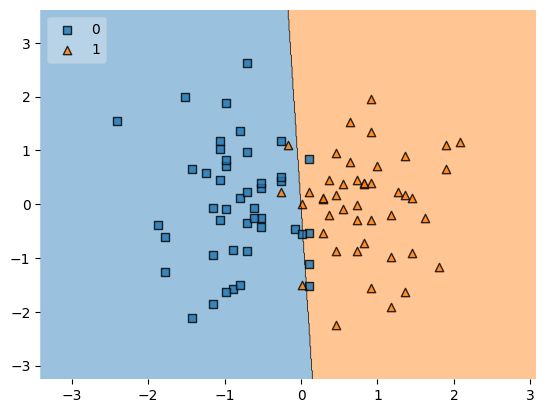

In [64]:
#plotting the decision regions
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(train_x, train_y.values, clf=clf, legend=2)

In [65]:
import pickle

In [66]:
pickle.dump(clf, open('model.pkl', 'wb'))